#  Project Insurance Cost Prediction

## 👤 Student Information

| Field           | Entry (fill in)                |
|-----------------|--------------------------------|
| **Name**        | _Ei Htoo Khaing, James Nguyen, Michelle_     |
| **Student #**   | _115400244,  ,_     |
| **Course/Section** |BDA500 NAA    |
| **Date**        | _2026-10-08_                   |


## Dataset: medical_cost_prediction_dataset.csv


## Step 1: Frame Both Questions

• Write one supervised question: What continuous value will the regression models predict?

• Explain the practical value of both analyses and identify likely risks or limitations.

__Supervised Question: How accurately can a patient's annual medical cost (USD) be predicted from demographics, lifestyle habits, and chronic health conditions?__


---


# Step 2: Load and Understand the Data
• Display head (), shape, info (), data types, summary statistics, and missing value counts.  
• Identify numeric, categorical, identifier, date, and potential leakage columns.  
• Document duplicate handling and any rows or columns removed, with reasons.  


In [3]:
# Eihtoo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("/Users/ACT/Downloads/medical_cost_prediction_dataset.csv")

display(df.head())
print("Shape:", df.shape)
df.info()

,age,gender,bmi,smoker,diabetes,hypertension,heart_disease,asthma,physical_activity_level,daily_steps,sleep_hours,stress_level,doctor_visits_per_year,hospital_admissions,medication_count,insurance_type,insurance_coverage_pct,city_type,previous_year_cost,annual_medical_cost
0,69,Male,29.4,No,1,0,0,0,Medium,14825,4.4,8,1,0,4,Private,80,Semi-Urban,10885,2645.50
1,32,Female,22.9,No,1,0,0,0,Medium,3620,6.0,7,4,3,0,Government,64,Semi-Urban,18722,10959.70
2,89,Male,25.7,No,0,0,0,0,High,10578,4.5,7,2,0,3,NaN,0,Urban,4196,8409.80
3,78,Male,31.9,Yes,0,1,0,0,Low,6226,8.6,9,6,1,7,Government,70,Urban,11128,7996.62
4,38,Male,27.7,No,0,0,0,0,High,6253,5.7,3,6,0,6,Private,77,Urban,15110,3202.52


Shape: (5000, 20)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      5000 non-null   int64  
 1   gender                   5000 non-null   str    
 2   bmi                      5000 non-null   float64
 3   smoker                   5000 non-null   str    
 4   diabetes                 5000 non-null   int64  
 5   hypertension             5000 non-null   int64  
 6   heart_disease            5000 non-null   int64  
 7   asthma                   5000 non-null   int64  
 8   physical_activity_level  5000 non-null   str    
 9   daily_steps              5000 non-null   int64  
 10  sleep_hours              5000 non-null   float64
 11  stress_level             5000 non-null   int64  
 12  doctor_visits_per_year   5000 non-null   int64  
 13  hospital_admissions      5000 non-null   int64  
 14  medication_count 

In [4]:
# Eihtoo
display(df.describe().T)                    # numeric
display(df.describe(include="str").T)    # categorical

print("Missing values per column:")
print(df.isna().sum())

,count,mean,std,min,25%,50%,75%,max
age,5000.0,53.299000,20.646851,18.00,36.0000,53.00,71.0000,89.0
bmi,5000.0,25.970820,5.046651,6.40,22.6000,25.90,29.4000,43.6
diabetes,5000.0,0.207600,0.405629,0.00,0.0000,0.00,0.0000,1.0
hypertension,5000.0,0.288000,0.452876,0.00,0.0000,0.00,1.0000,1.0
heart_disease,5000.0,0.142200,0.349290,0.00,0.0000,0.00,0.0000,1.0
asthma,5000.0,0.096400,0.295169,0.00,0.0000,0.00,0.0000,1.0
daily_steps,5000.0,7993.216800,4052.127069,1004.00,4545.0000,7989.00,11532.2500,14999.0
sleep_hours,5000.0,6.488140,1.443361,4.00,5.2000,6.50,7.7000,9.0
stress_level,5000.0,5.475400,2.892312,1.00,3.0000,5.00,8.0000,10.0
doctor_visits_per_year,5000.0,4.030600,2.010689,0.00,3.0000,4.00,5.0000,14.0


,count,unique,top,freq
gender,5000,2,Female,2519
smoker,5000,2,No,3779
physical_activity_level,5000,3,Low,1996
insurance_type,3952,2,Private,1979
city_type,5000,3,Urban,2474


Missing values per column:
age                           0
gender                        0
bmi                           0
smoker                        0
diabetes                      0
hypertension                  0
heart_disease                 0
asthma                        0
physical_activity_level       0
daily_steps                   0
sleep_hours                   0
stress_level                  0
doctor_visits_per_year        0
hospital_admissions           0
medication_count              0
insurance_type             1048
insurance_coverage_pct        0
city_type                     0
previous_year_cost            0
annual_medical_cost           0
dtype: int64


• Identify numeric, categorical, identifier, date, and potential leakage columns.  

In [5]:
# Eihtoo
target = ["annual_medical_cost"] # the target column

leakage_cols = [
    "previous_year_cost",       # last year's cost, copy of target column
    "doctor_visits_per_year",   # utilization happens alongside cost
    "hospital_admissions",
    "medication_count",
    "insurance_type",           # coverage directly reduces final cost
    "insurance_coverage_pct",
]

numeric_cols = [c for c in df.select_dtypes(include="number").columns if c not in leakage_cols + target] # identify numerical columns
categorical_cols = [c for c in df.select_dtypes(include="str").columns if c not in leakage_cols + target] # identify categorical columns

identifier_cols = []   # none in this dataset
date_cols = []         # none in this dataset

print("Target:", target)
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
print("Identifier:", identifier_cols)
print("Date:", date_cols)
print("Potential leakage:", leakage_cols)

Target: ['annual_medical_cost']
Numeric: ['age', 'bmi', 'diabetes', 'hypertension', 'heart_disease', 'asthma', 'daily_steps', 'sleep_hours', 'stress_level']
Categorical: ['gender', 'smoker', 'physical_activity_level', 'city_type']
Identifier: []
Date: []
Potential leakage: ['previous_year_cost', 'doctor_visits_per_year', 'hospital_admissions', 'medication_count', 'insurance_type', 'insurance_coverage_pct']


• Document duplicate handling and any rows or columns removed, with reasons.  

In [6]:
# Eihtoo
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)

df_clean = df.drop_duplicates().drop(columns=leakage_cols) # drop the duplicates as well as the potential leakage columns
print("Shape before:", df.shape)
print("Shape after:", df_clean.shape)

Duplicate rows: 0
Shape before: (5000, 20)
Shape after: (5000, 14)


### Data Cleaning Notes  
- **Duplicates:** Found 0 duplicate rows.  
- **Missing values:** None found, so no imputation needed.  
- **Identifier and date columns:** None present in this dataset.  
- **Columns removed (6):** previous_year_cost, doctor_visits_per_year, hospital_admissions, medication_count, insurance_type, insurance_coverage_pct.  
  - Reason: these are measured alongside or after healthcare costs happen, or directly change the final cost. Keeping them would leak target information and make the model look more accurate than it would be in real use.  
- **Final shape:** 5000 rows × 14 columns (13 features + target).  

## Step 3: Exploratory Data Analysis  
• Create histograms and boxplots for important numeric features.  
• Create a correlation heatmap for numeric variables.  
• Create at least two plots relating important predictors to the regression target.

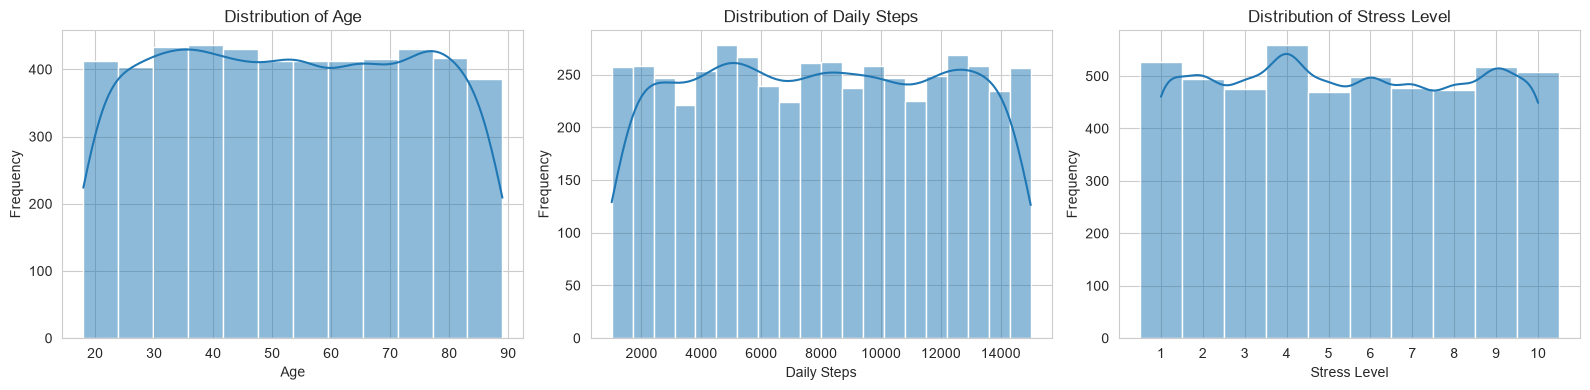

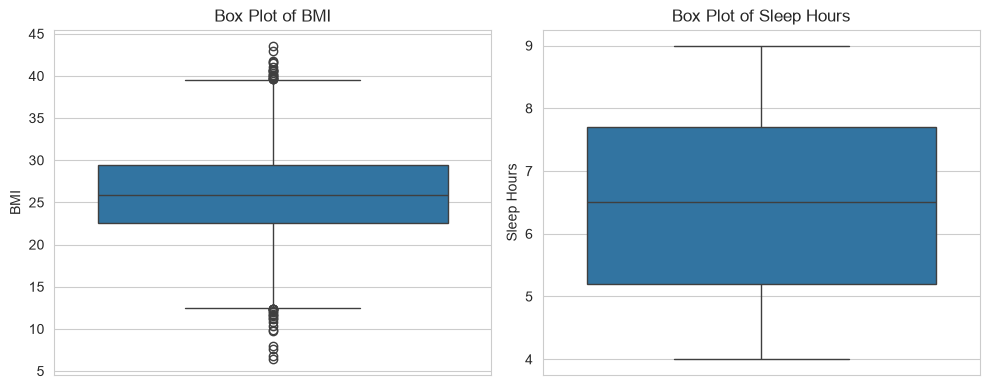

In [7]:
# James Nguyen
import seaborn as sns

# Set the visual style
sns.set_style("whitegrid")

# 1. Histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Age
sns.histplot(
    data=df, x='age',
    bins=12, kde=True,
    ax=axes[0]
)
axes[0].set_title('Distribution of Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Daily steps
sns.histplot(
    data=df, x='daily_steps',
    bins=20, kde=True,
    ax=axes[1]
)
axes[1].set_title('Distribution of Daily Steps')
axes[1].set_xlabel('Daily Steps')
axes[1].set_ylabel('Frequency')

# Stress level: discrete ratings
sns.histplot(
    data=df, x='stress_level',
    discrete=True,
    kde=True,
    ax=axes[2]
)
axes[2].set_title('Distribution of Stress Level')
axes[2].set_xlabel('Stress Level')
axes[2].set_ylabel('Frequency')
axes[2].set_xticks(range(1, 11))

plt.tight_layout()
plt.show()


# 2. Box plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(data=df, y='bmi', ax=axes[0])
axes[0].set_title('Box Plot of BMI')
axes[0].set_ylabel('BMI')

sns.boxplot(data=df, y='sleep_hours', ax=axes[1])
axes[1].set_title('Box Plot of Sleep Hours')
axes[1].set_ylabel('Sleep Hours')

plt.tight_layout()
plt.show()


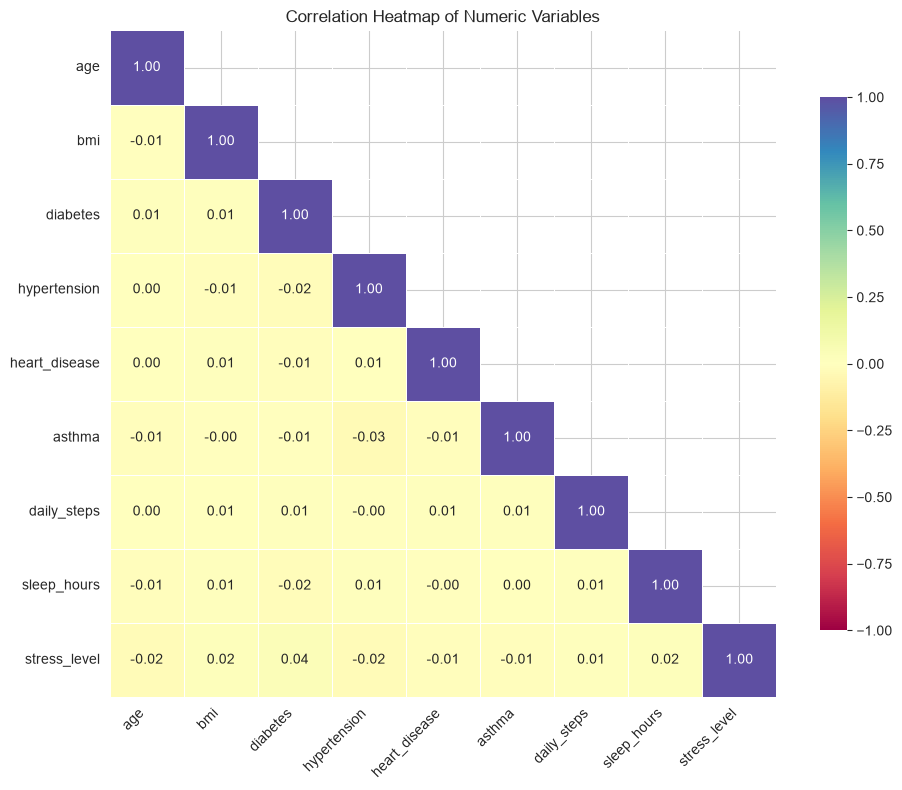

In [ ]:
# James Nguyen
# Calculate the correlation matrix
corr_matrix = df[numeric_cols].corr()

# Mask the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='Spectral',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Correlation Heatmap of Numeric Variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

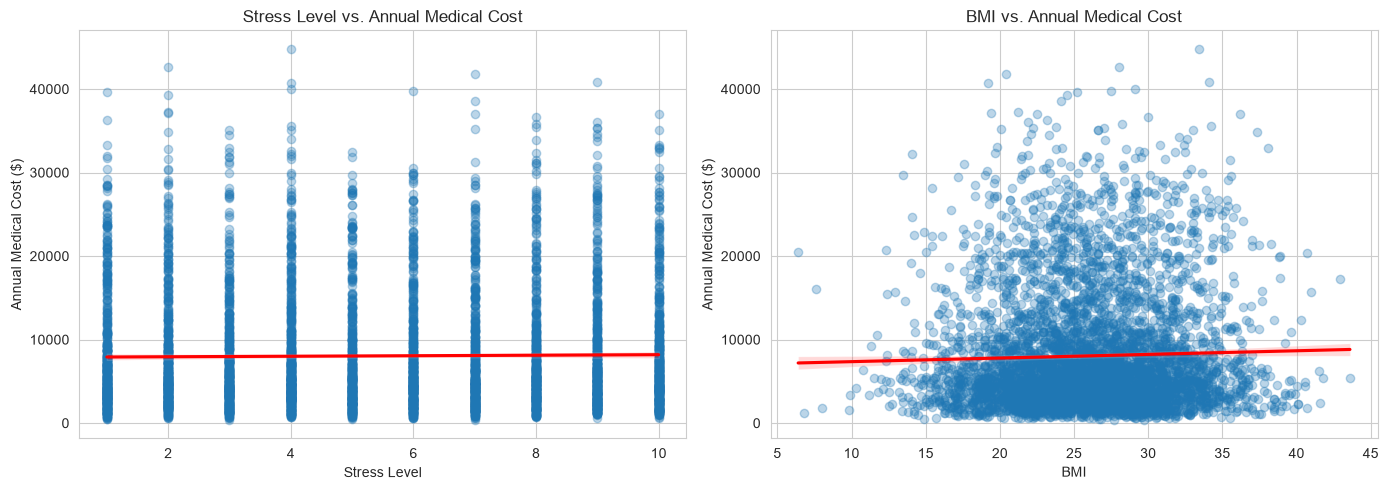

In [8]:
# James Nguyen
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stress level vs. annual medical cost
sns.regplot(
    data=df,
    x='stress_level',
    y='annual_medical_cost',
    ax=axes[0],
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

axes[0].set_title('Stress Level vs. Annual Medical Cost')
axes[0].set_xlabel('Stress Level')
axes[0].set_ylabel('Annual Medical Cost ($)')

# BMI vs. annual medical cost
sns.regplot(
    data=df,
    x='bmi',
    y='annual_medical_cost',
    ax=axes[1],
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

axes[1].set_title('BMI vs. Annual Medical Cost')
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Annual Medical Cost ($)')

plt.tight_layout()
plt.show()

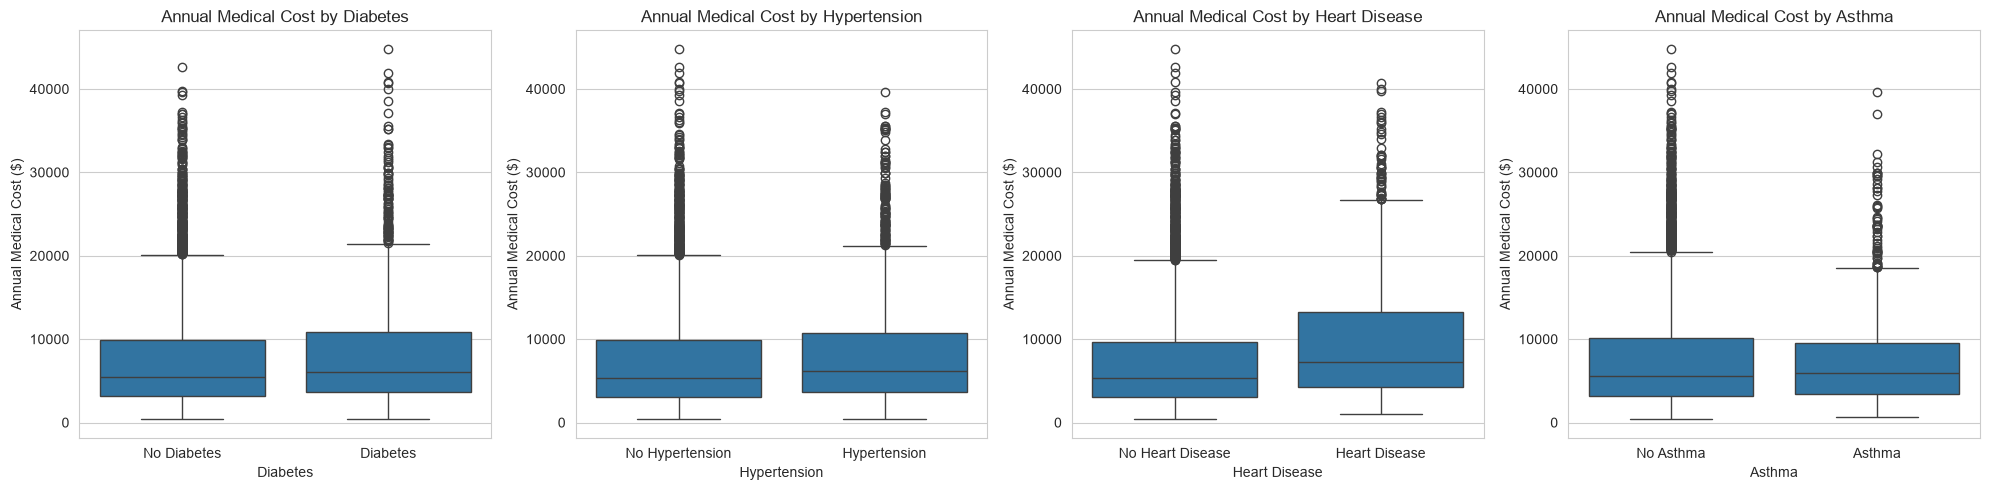

In [ ]:
# James Nguyen
features = ['diabetes', 'hypertension', 'heart_disease', 'asthma']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
labels = {
    'diabetes': ['No Diabetes', 'Diabetes'],
    'hypertension': ['No Hypertension', 'Hypertension'],
    'heart_disease': ['No Heart Disease', 'Heart Disease'],
    'asthma': ['No Asthma', 'Asthma']
}

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x=feature,
        y='annual_medical_cost',
        ax=ax
    )

    ax.set_title(f'Annual Medical Cost by {feature.replace("_", " ").title()}')
    ax.set_xlabel(feature.replace('_', ' ').title())
    ax.set_ylabel('Annual Medical Cost ($)')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels[feature])

plt.tight_layout()
plt.show()

## Step 4: Prepare Features  
• Handle missing values using a justified strategy.  
• Encode categorical variables using OneHotEncoder or justified ordinal encoding.  
• Scale numeric features using StandardScaler or justify MinMaxScaler..

In [9]:
# James Nguyen
from sklearn.preprocessing import OneHotEncoder

categorical = [
    'gender',
    'smoker',
    'physical_activity_level',
    'city_type'
]

# Define the expected categories and their order
categories = [
    ['Male', 'Female'],
    ['Yes', 'No'],
    ['Low', 'Medium', 'High'],
    ['Urban', 'Semi-urban', 'Rural']
]

# Initialize the encoder
encoder = OneHotEncoder(
    categories=categories,
    handle_unknown='ignore',
    sparse_output=False
)

# Fit and transform categorical columns
encoded_array = encoder.fit_transform(df[categorical])

# Create a DataFrame with encoded column names
encoded_columns = encoder.get_feature_names_out(categorical)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=df.index
)

# Replace original categorical columns with encoded columns
df = pd.concat(
    [df.drop(columns=categorical), encoded_df],
    axis=1
)

print(df.head())
print(df.columns.tolist())

   age   bmi  diabetes  hypertension  heart_disease  asthma  daily_steps  \
0   69  29.4         1             0              0       0        14825   
1   32  22.9         1             0              0       0         3620   
2   89  25.7         0             0              0       0        10578   
3   78  31.9         0             1              0       0         6226   
4   38  27.7         0             0              0       0         6253   

   sleep_hours  stress_level  doctor_visits_per_year  ...  gender_Male  \
0          4.4             8                       1  ...          1.0   
1          6.0             7                       4  ...          0.0   
2          4.5             7                       2  ...          1.0   
3          8.6             9                       6  ...          1.0   
4          5.7             3                       6  ...          1.0   

   gender_Female smoker_Yes  smoker_No  physical_activity_level_Low  \
0            0.0        0.0

In [8]:
# James Nguyen
from sklearn.preprocessing import StandardScaler

# Continuous numeric predictors
numeric_features = [
    'age',
    'bmi',
    'daily_steps',
    'sleep_hours',
    'stress_level'
]
# Initialize scaler
scaler = StandardScaler()

# Scale continuous features
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# Verify the scaling
print("Scaled feature means:")
print(df[numeric_features].mean().round(3))

print("\nScaled feature standard deviations:")
print(df[numeric_features].std().round(3))

print("\nScaled data preview:")
print(df[numeric_features].head())

Scaled feature means:
age             0.0
bmi             0.0
daily_steps    -0.0
sleep_hours     0.0
stress_level    0.0
dtype: float64

Scaled feature standard deviations:
age             1.0
bmi             1.0
daily_steps     1.0
sleep_hours     1.0
stress_level    1.0
dtype: float64

Scaled data preview:
        age       bmi  daily_steps  sleep_hours  stress_level
0  0.760531  0.679564     1.686143    -1.446866      0.872953
1 -1.031689 -0.608548    -1.079348    -0.338231      0.527174
2  1.729299 -0.053669     0.637947    -1.377576      0.527174
3  1.196476  1.174992    -0.436164     1.463301      1.218732
4 -0.741059  0.342673    -0.429501    -0.546100     -0.855941


## Step 5: Build Configuration  
• Use ColumnTransformer to combine numeric and categorical preprocessing.  
• Create train/test split, recommended test % given in the table below.  
• Fit regression preprocessing only on the training data, then transform validation or test data without refitting.  
• Use cross-validation numbers given in the table below on the training data for comparison and tuning.

In [10]:
print(df.columns.tolist())
display(df.head())

['age', 'bmi', 'diabetes', 'hypertension', 'heart_disease', 'asthma', 'daily_steps', 'sleep_hours', 'stress_level', 'doctor_visits_per_year', 'hospital_admissions', 'medication_count', 'insurance_type', 'insurance_coverage_pct', 'previous_year_cost', 'annual_medical_cost', 'gender_Male', 'gender_Female', 'smoker_Yes', 'smoker_No', 'physical_activity_level_Low', 'physical_activity_level_Medium', 'physical_activity_level_High', 'city_type_Urban', 'city_type_Semi-urban', 'city_type_Rural']


,age,bmi,diabetes,hypertension,heart_disease,asthma,daily_steps,sleep_hours,stress_level,doctor_visits_per_year,...,gender_Male,gender_Female,smoker_Yes,smoker_No,physical_activity_level_Low,physical_activity_level_Medium,physical_activity_level_High,city_type_Urban,city_type_Semi-urban,city_type_Rural
0,69,29.4,1,0,0,0,14825,4.4,8,1,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,32,22.9,1,0,0,0,3620,6.0,7,4,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,89,25.7,0,0,0,0,10578,4.5,7,2,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
3,78,31.9,0,1,0,0,6226,8.6,9,6,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,38,27.7,0,0,0,0,6253,5.7,3,6,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0


In [11]:
# James Nguyen
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Existing numeric columns (already scaled)
numeric_cols = [
    "age", "bmi", "diabetes", "hypertension",
    "heart_disease", "asthma", "daily_steps",
    "sleep_hours", "stress_level"
]

# Existing one-hot-encoded categorical columns
categorical_encoded_cols = [
    col for col in df.columns
    if col.startswith((
        "gender_",
        "smoker_",
        "physical_activity_level_",
        "city_type_"
    ))
]

# Define X and y from the current dataframe
X = df[numeric_cols + categorical_encoded_cols].copy()
y = df[target].copy()

# ColumnTransformer combines the two existing feature groups.
preproc = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
    ("cat", "passthrough", categorical_encoded_cols)
])

model = Pipeline([
    ("preprocessor", preproc),
    ("regressor", LinearRegression())
])
models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preproc),
        ('regressor', LinearRegression())
    ]),

    'Ridge Regression': Pipeline([
        ('preprocessor', preproc),
        ('regressor', Ridge(alpha=1.0))
    ]),

    'Polynomial Regression': Pipeline([
        ('preprocessor', preproc),
        ('polynomial', PolynomialFeatures(
            degree=3,
            include_bias=False
        )),
        ('regressor', LinearRegression())
    ])
}

In [13]:
# James Nguyen
test_size = 0.10
random_states = [0, 42]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

cv_results = []
test_results = []

for model_name, model in models.items():
    for rs in random_states:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=rs
        )
        # Five-fold cross-validation on training data only
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )
        cv_results.append({
            'Model': model_name,
            'Test Size': test_size,
            'Random State': rs,
            'CV MAE Mean': - scores['test_mae'].mean(),
            'CV MAE Std': scores['test_mae'].std(ddof=1),
            'CV RMSE Mean': - scores['test_rmse'].mean(),
            'CV RMSE Std': scores['test_rmse'].std(ddof=1),
            'CV R2 Mean': scores['test_r2'].mean(),
            'CV R2 Std': scores['test_r2'].std(ddof=1)
        })

        # Fit on the full training split, then evaluate on held-out test data
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        test_results.append({
            'Model': model_name,
            'Test Size': test_size,
            'Random State': rs,
            'Test MAE': mean_absolute_error(y_test, y_pred),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
            'Test R2': r2_score(y_test, y_pred)
        })

cv_summary = pd.DataFrame(cv_results)
test_summary = pd.DataFrame(test_results)

print("CROSS-VALIDATION RESULTS")
display(cv_summary.round(4))

print("TEST SET RESULTS")
display(test_summary.round(4))

CROSS-VALIDATION RESULTS


,Model,Test Size,Random State,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,Linear Regression,0.1,0,5311.1935,170.7054,7069.4703,271.8080,0.0123,0.0213
1,Linear Regression,0.1,42,5250.2874,178.9026,7008.1660,239.4852,0.0199,0.0106
2,Ridge Regression,0.1,0,5311.1398,170.7940,7069.4223,271.9083,0.0123,0.0212
3,Ridge Regression,0.1,42,5250.2420,178.8333,7008.1358,239.4771,0.0199,0.0105
4,Polynomial Regression,0.1,0,5333.9217,189.8857,7110.6850,296.4244,0.0011,0.0152
5,Polynomial Regression,0.1,42,5276.0023,162.7697,7054.0009,236.3225,0.0070,0.0117


TEST SET RESULTS


,Model,Test Size,Random State,Test MAE,Test RMSE,Test R2
0,Linear Regression,0.1,0,4931.6914,6458.2725,0.0179
1,Linear Regression,0.1,42,5276.6173,6918.3449,0.0098
2,Ridge Regression,0.1,0,4931.6812,6458.2478,0.0179
3,Ridge Regression,0.1,42,5276.6032,6918.3297,0.0098
4,Polynomial Regression,0.1,0,4914.9703,6444.3573,0.0221
5,Polynomial Regression,0.1,42,5288.0736,6966.8901,-0.0041


In [14]:
# James Nguyen
cv_summary_10 = cv_summary.copy()
test_summary_10 = test_summary.copy()

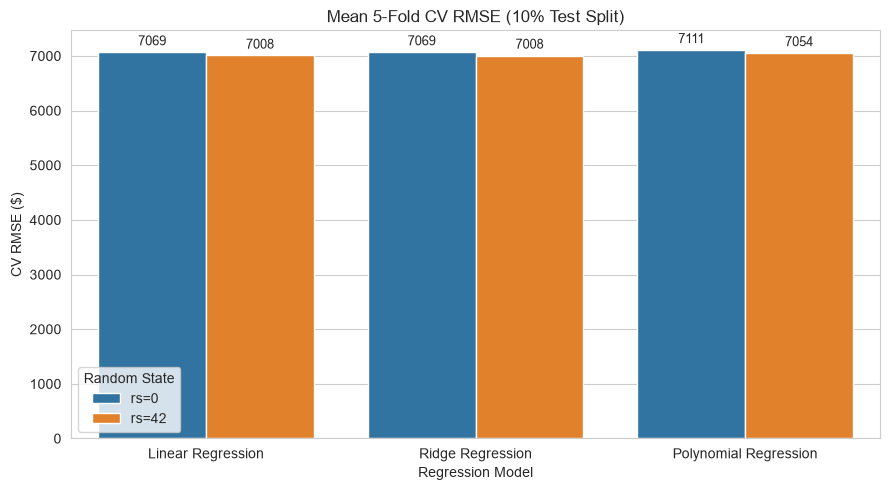

In [15]:
# Compare mean CV RMSE for each model and random state

plot_10 = cv_summary_10.copy()
plot_10["Config"] = "rs=" + plot_10["Random State"].astype(str)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=plot_10,
    x="Model",
    y="CV RMSE Mean",
    hue="Config",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

ax.set_title("Mean 5-Fold CV RMSE (10% Test Split)")
ax.set_xlabel("Regression Model")
ax.set_ylabel("CV RMSE ($)")
ax.legend(title="Random State")
plt.tight_layout()
plt.show()

### Test size 25%


In [27]:
# Michelle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, PolynomialFeatures
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.base import clone

# Reload the original dataset
df25 = pd.read_csv("medical_cost_prediction_dataset.csv")

target_col = "annual_medical_cost"

leakage_cols = [
    "previous_year_cost",
    "doctor_visits_per_year",
    "hospital_admissions",
    "medication_count",
    "insurance_type",
    "insurance_coverage_pct"
]

df25 = df25.drop_duplicates().drop(columns=leakage_cols)

numeric_features = [
    "age", "bmi", "diabetes", "hypertension",
    "heart_disease", "asthma", "daily_steps",
    "sleep_hours", "stress_level"
]

categorical_features = [
    "gender", "smoker",
    "physical_activity_level", "city_type"
]

X = df25[numeric_features + categorical_features]
y = df25[target_col]
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [28]:
# Michelle
# TEST SIZE 25%: LINEAR, RIDGE, AND POLYNOMIAL REGRESSION

models = {
    "Linear Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", Ridge())
    ]),

    "Polynomial Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("polynomial", PolynomialFeatures(
            degree=3, include_bias=False
        )),
        ("regressor", LinearRegression())
    ])
}

ridge_param_grid = {
    "regressor__alpha": [0.1, 1.0, 10.0, 100.0]
}

test_size = 0.25
random_states = [0, 42]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

cv_results_25 = []
test_results_25 = []

for model_name, base_model in models.items():

    for rs in random_states:

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=rs
        )

        model = clone(base_model)

        if model_name == "Ridge Regression":
            search = GridSearchCV(
                estimator=model,
                param_grid=ridge_param_grid,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                n_jobs=-1,
                refit=True
            )
            search.fit(X_train, y_train)
            fitted_model = search.best_estimator_
            best_params = search.best_params_

            # Best cross-validated RMSE from alpha tuning
            best_cv_rmse = -search.best_score_

            # Obtain the remaining CV metrics using the selected alpha
            scores = cross_validate(
                clone(fitted_model),
                X_train, y_train,
                cv=cv, scoring=scoring, n_jobs=-1
            )

        else:
            scores = cross_validate(
                model, X_train, y_train,
                cv=cv, scoring=scoring, n_jobs=-1
            )

            fitted_model = clone(model)
            fitted_model.fit(X_train, y_train)
            best_params = {"model": "default"}

            best_cv_rmse = -scores["test_rmse"].mean()

        # Fit the final model for this split and evaluate on test data
        if model_name != "Ridge Regression":
            # cross_validate does not fit the model passed to it
            fitted_model.fit(X_train, y_train)

        y_pred = fitted_model.predict(X_test)

        cv_results_25.append({
            "Model": model_name,
            "Test Size": test_size,
            "Random State": rs,
            "CV MAE Mean": -scores["test_mae"].mean(),
            "CV MAE Std": scores["test_mae"].std(ddof=1),
            "CV RMSE Mean": best_cv_rmse,
            "CV RMSE Std": scores["test_rmse"].std(ddof=1),
            "CV R2 Mean": scores["test_r2"].mean(),
            "CV R2 Std": scores["test_r2"].std(ddof=1),
            "Best Parameters": str(best_params)})

        test_results_25.append({
            "Model": model_name,
            "Test Size": test_size,
            "Random State": rs,
            "Test MAE": mean_absolute_error(y_test, y_pred),
            "Test RMSE": np.sqrt(
                mean_squared_error(y_test, y_pred)
            ),
            "Test R2": r2_score(y_test, y_pred)})

cv_summary_25 = pd.DataFrame(cv_results_25)
test_summary_25 = pd.DataFrame(test_results_25)

print("25% TEST SPLIT — FIVE-FOLD CROSS-VALIDATION")
display(cv_summary_25.round(4))

print("25% TEST SPLIT — HELD-OUT TEST RESULTS")
display(test_summary_25.round(4))

25% TEST SPLIT — FIVE-FOLD CROSS-VALIDATION


,Model,Test Size,Random State,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std,Best Parameters
0,Linear Regression,0.25,0,5391.1380,159.4648,7140.4242,352.6608,0.0148,0.0173,{'model': 'default'}
1,Linear Regression,0.25,42,5212.5112,124.5062,7000.2056,166.4284,0.0149,0.0101,{'model': 'default'}
2,Ridge Regression,0.25,0,5389.2060,160.2593,7138.3795,354.5933,0.0154,0.0166,{'regressor__alpha': 100.0}
3,Ridge Regression,0.25,42,5210.1863,124.5143,6998.7242,167.0369,0.0154,0.0094,{'regressor__alpha': 100.0}
4,Polynomial Regression,0.25,0,6197.8300,235.4986,8329.9683,464.0810,-0.3417,0.0732,{'model': 'default'}
5,Polynomial Regression,0.25,42,6026.0853,275.7173,8140.0165,379.5815,-0.3315,0.0654,{'model': 'default'}


25% TEST SPLIT — HELD-OUT TEST RESULTS


,Model,Test Size,Random State,Test MAE,Test RMSE,Test R2
0,Linear Regression,0.25,0,4965.7356,6595.0464,0.0111
1,Linear Regression,0.25,42,5316.5932,7009.5947,0.0282
2,Ridge Regression,0.25,0,4963.4601,6592.5551,0.0119
3,Ridge Regression,0.25,42,5316.8904,7009.8499,0.0281
4,Polynomial Regression,0.25,0,5611.2086,7545.0031,-0.2943
5,Polynomial Regression,0.25,42,5703.7728,7623.9636,-0.1496


##Step 2: Complete Python code for the 25% experiment

In [29]:
# Michelle
# TEST SIZE 25%: LINEAR, RIDGE, AND POLYNOMIAL REGRESSION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Define features and target using the cleaned, original data
target_col = "annual_medical_cost"

numeric_features = [
    "age", "bmi", "diabetes", "hypertension",
    "heart_disease", "asthma", "daily_steps",
    "sleep_hours", "stress_level"
]

categorical_features = [
    "gender", "smoker",
    "physical_activity_level", "city_type"
]

X = df_clean[numeric_features + categorical_features].copy()
y = df_clean[target_col].copy()

# 2. Define preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 3. Define the three regression models
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0))
    ]),

    "Polynomial Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("polynomial", PolynomialFeatures(
            degree=3, include_bias=False
        )),
        ("regressor", LinearRegression())
    ])
}

# 4. Set experiment configuration
test_size_25 = 0.25
random_states_25 = [0, 42]

cv_25 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_25 = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

model_params = {
    "Linear Regression": "default",
    "Ridge Regression": "alpha=1.0",
    "Polynomial Regression": "degree=3"
}

# 5. Run five-fold CV on each training split
cv_results_25 = []
test_results_25 = []

for model_name, base_model in models.items():
    for rs in random_states_25:

        X_train_25, X_test_25, y_train_25, y_test_25 = (
            train_test_split(
                X, y,
                test_size=test_size_25,
                random_state=rs
            )
        )

        # Cross-validation uses training data only
        scores = cross_validate(
            clone(base_model),
            X_train_25,
            y_train_25,
            cv=cv_25,
            scoring=scoring_25,
            n_jobs=-1
        )

        cv_results_25.append({
            "Model": model_name,
            "Params": model_params[model_name],
            "Test Size": test_size_25,
            "Random State": rs,
            "Train Rows": len(X_train_25),
            "CV MAE Mean": -scores["test_mae"].mean(),
            "CV MAE Std": scores["test_mae"].std(ddof=1),
            "CV RMSE Mean": -scores["test_rmse"].mean(),
            "CV RMSE Std": scores["test_rmse"].std(ddof=1),
            "CV R2 Mean": scores["test_r2"].mean(),
            "CV R2 Std": scores["test_r2"].std(ddof=1)
        })

        # Fit a fresh model and evaluate on the held-out test set
        fitted_model = clone(base_model)
        fitted_model.fit(X_train_25, y_train_25)
        y_pred_25 = fitted_model.predict(X_test_25)

        test_results_25.append({
            "Model": model_name,
            "Test Size": test_size_25,
            "Random State": rs,
            "Test MAE": mean_absolute_error(y_test_25, y_pred_25),
            "Test RMSE": np.sqrt(
                mean_squared_error(y_test_25, y_pred_25)
            ),
            "Test R2": r2_score(y_test_25, y_pred_25)
        })

# 6. Display and save results
cv_summary_25 = pd.DataFrame(cv_results_25)
test_summary_25 = pd.DataFrame(test_results_25)

print("CROSS-VALIDATION RESULTS: 25% TEST SIZE")
display(cv_summary_25.round(4))

print("HELD-OUT TEST RESULTS: 25% TEST SIZE")
display(test_summary_25.round(4))

CROSS-VALIDATION RESULTS: 25% TEST SIZE


,Model,Params,Test Size,Random State,Train Rows,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,Linear Regression,default,0.25,0,3750,5391.1380,159.4648,7140.4242,352.6608,0.0148,0.0173
1,Linear Regression,default,0.25,42,3750,5212.5112,124.5062,7000.2056,166.4284,0.0149,0.0101
2,Ridge Regression,alpha=1.0,0.25,0,3750,5391.1163,159.4726,7140.3996,352.6814,0.0148,0.0173
3,Ridge Regression,alpha=1.0,0.25,42,3750,5212.4820,124.5035,7000.1873,166.4350,0.0149,0.0101
4,Polynomial Regression,degree=3,0.25,0,3750,6197.8300,235.4986,8329.9683,464.0810,-0.3417,0.0732
5,Polynomial Regression,degree=3,0.25,42,3750,6026.0853,275.7173,8140.0165,379.5815,-0.3315,0.0654


HELD-OUT TEST RESULTS: 25% TEST SIZE


,Model,Test Size,Random State,Test MAE,Test RMSE,Test R2
0,Linear Regression,0.25,0,4965.7356,6595.0464,0.0111
1,Linear Regression,0.25,42,5316.5932,7009.5947,0.0282
2,Ridge Regression,0.25,0,4965.7108,6595.0184,0.0111
3,Ridge Regression,0.25,42,5316.5946,7009.5951,0.0282
4,Polynomial Regression,0.25,0,5611.2086,7545.0031,-0.2943
5,Polynomial Regression,0.25,42,5703.7728,7623.9636,-0.1496


##Step 3: Visualize the 25% cross-validation results

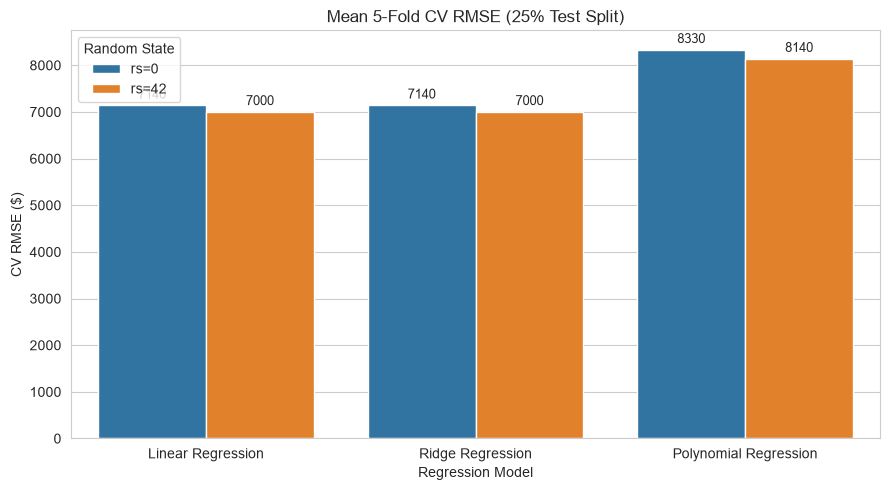

In [30]:
# Michelle
# Compare mean CV RMSE for each model and random state

plot_25 = cv_summary_25.copy()
plot_25["Config"] = "rs=" + plot_25["Random State"].astype(str)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=plot_25,
    x="Model",
    y="CV RMSE Mean",
    hue="Config",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

ax.set_title("Mean 5-Fold CV RMSE (25% Test Split)")
ax.set_xlabel("Regression Model")
ax.set_ylabel("CV RMSE ($)")
ax.legend(title="Random State")
plt.tight_layout()
plt.show()

### Test size 30%
*Contributor: Ei Htoo Khaing*

Each of the three models (Linear, Ridge with alpha = 1.0, Polynomial degree 3) is run with a 30% test split and random states 0 and 42, giving 6 configurations. For every configuration:

- the data is split 70/30,
- 5-fold cross-validation is run **on the 70% training part only**,
- MAE, RMSE and R² are averaged across the 5 folds, with their standard deviations.

The 30% test portion is not touched here. It is only used later, once, for the selected model.

In [24]:
# Ei Htoo Khaing
# Test size 30%
from sklearn.base import clone

test_size_30 = 0.30
random_states_30 = [0, 42]

# Same 5-fold setup as the 10% section so results are comparable
cv_30 = KFold(n_splits=5, shuffle=True, random_state=42)

scoring_30 = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

model_params = {
    "Linear Regression": "default",
    "Ridge Regression": "alpha=1.0",
    "Polynomial Regression": "degree=3"
}

cv_results_30 = []

for model_name, base_model in models.items():
    for rs in random_states_30:
        X_train_30, X_test_30, y_train_30, y_test_30 = train_test_split(
            X, y,
            test_size=test_size_30,
            random_state=rs
        )

        # clone() gives a fresh, unfitted copy of the pipeline for each configuration
        scores = cross_validate(
            clone(base_model),
            X_train_30,
            y_train_30,
            cv=cv_30,
            scoring=scoring_30,
            n_jobs=-1
        )

        cv_results_30.append({
            "Model": model_name,
            "Params": model_params[model_name],
            "Test Size": test_size_30,
            "Random State": rs,
            "Train Rows": len(X_train_30),
            "CV MAE Mean": -scores["test_mae"].mean(),
            "CV MAE Std": scores["test_mae"].std(ddof=1),
            "CV RMSE Mean": -scores["test_rmse"].mean(),
            "CV RMSE Std": scores["test_rmse"].std(ddof=1),
            "CV R2 Mean": scores["test_r2"].mean(),
            "CV R2 Std": scores["test_r2"].std(ddof=1)
        })

cv_summary_30 = pd.DataFrame(cv_results_30)

print("CROSS-VALIDATION RESULTS, TEST SIZE 30%")
display(cv_summary_30.round(4))

CROSS-VALIDATION RESULTS, TEST SIZE 30%


,Model,Params,Test Size,Random State,Train Rows,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,Linear Regression,default,0.3,0,3500,5352.5662,207.1917,7105.9577,432.2273,0.0168,0.0076
1,Linear Regression,default,0.3,42,3500,5212.9829,137.8356,7005.0370,208.1757,0.0131,0.0144
2,Ridge Regression,alpha=1.0,0.3,0,3500,5352.5470,207.1967,7105.9265,432.2252,0.0168,0.0076
3,Ridge Regression,alpha=1.0,0.3,42,3500,5212.9421,137.8507,7005.0124,208.1745,0.0131,0.0144
4,Polynomial Regression,degree=3,0.3,0,3500,6206.5672,161.7817,8291.2561,279.1359,-0.3447,0.1055
5,Polynomial Regression,degree=3,0.3,42,3500,6075.0964,195.1933,8206.7132,394.9380,-0.3573,0.1232


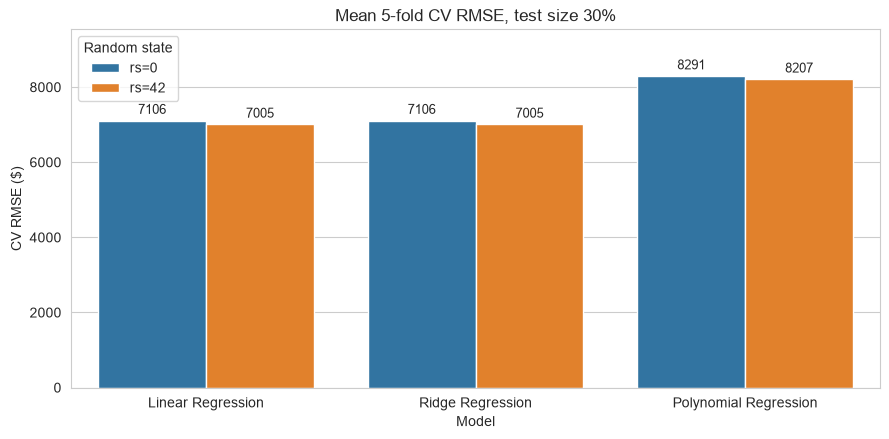

In [25]:
# Ei Htoo Khaing
# Quick visual check of the 30% configurations
plot_30 = cv_summary_30.copy()
plot_30["Config"] = "rs=" + plot_30["Random State"].astype(str)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_30, x="Model", y="CV RMSE Mean", hue="Config", ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

ax.set_title("Mean 5-fold CV RMSE, test size 30%")
ax.set_xlabel("Model")
ax.set_ylabel("CV RMSE ($)")
ax.legend(title="Random state")
ax.set_ylim(0, plot_30["CV RMSE Mean"].max() * 1.15)
plt.tight_layout()
plt.show()

## Regression Evaluation

### Comparison of all configurations
All cross-validation tables (10%, 25%, 30%) are combined into one comparison table. 

In [31]:
# Eihtoo
# Combine every CV summary that exists | Contributor: Ei Htoo Khaing
cv_parts = []
for name in ["cv_summary_10", "cv_summary_25", "cv_summary_30"]:
    if name in globals():
        part = globals()[name].copy()
        if "Params" not in part.columns:
            part["Params"] = part["Model"].map(model_params)
        cv_parts.append(part)
    else:
        print(f"Warning: {name} not found, skipping it.")

all_cv = pd.concat(cv_parts, ignore_index=True)
all_cv["Config"] = (
    (all_cv["Test Size"] * 100).round().astype(int).astype(str) + "% / rs="
    + all_cv["Random State"].astype(str)
)

print("ALL CONFIGURATIONS")
display(
    all_cv[["Model", "Params", "Config", "CV MAE Mean", "CV MAE Std",
            "CV RMSE Mean", "CV RMSE Std", "CV R2 Mean", "CV R2 Std"]].round(4)
)

# Average each model across all of its configurations
model_comparison = (
    all_cv.groupby("Model", sort=False)
    .agg(
        Configs=("Config", "count"),
        MAE=("CV MAE Mean", "mean"),
        RMSE=("CV RMSE Mean", "mean"),
        RMSE_Std_Across_Configs=("CV RMSE Mean", "std"),
        R2=("CV R2 Mean", "mean")
    )
    .sort_values("RMSE")
)

print("MODEL COMPARISON (average over all configurations)")
display(model_comparison.round(4))

ALL CONFIGURATIONS


,Model,Params,Config,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,Linear Regression,default,10% / rs=0,5311.1935,170.7054,7069.4703,271.8080,0.0123,0.0213
1,Linear Regression,default,10% / rs=42,5250.2874,178.9026,7008.1660,239.4852,0.0199,0.0106
2,Ridge Regression,alpha=1.0,10% / rs=0,5311.1398,170.7940,7069.4223,271.9083,0.0123,0.0212
3,Ridge Regression,alpha=1.0,10% / rs=42,5250.2420,178.8333,7008.1358,239.4771,0.0199,0.0105
4,Polynomial Regression,degree=3,10% / rs=0,5333.9217,189.8857,7110.6850,296.4244,0.0011,0.0152
5,Polynomial Regression,degree=3,10% / rs=42,5276.0023,162.7697,7054.0009,236.3225,0.0070,0.0117
6,Linear Regression,default,25% / rs=0,5391.1380,159.4648,7140.4242,352.6608,0.0148,0.0173
7,Linear Regression,default,25% / rs=42,5212.5112,124.5062,7000.2056,166.4284,0.0149,0.0101
8,Ridge Regression,alpha=1.0,25% / rs=0,5391.1163,159.4726,7140.3996,352.6814,0.0148,0.0173
9,Ridge Regression,alpha=1.0,25% / rs=42,5212.4820,124.5035,7000.1873,166.4350,0.0149,0.0101


MODEL COMPARISON (average over all configurations)


,Configs,MAE,RMSE,RMSE_Std_Across_Configs,R2
Model,,,,,
Ridge Regression,6,5288.4115,7054.8473,59.6555,0.0153
Linear Regression,6,5288.4465,7054.8768,59.6581,0.0153
Polynomial Regression,6,5852.5838,7855.4400,602.7361,-0.2279


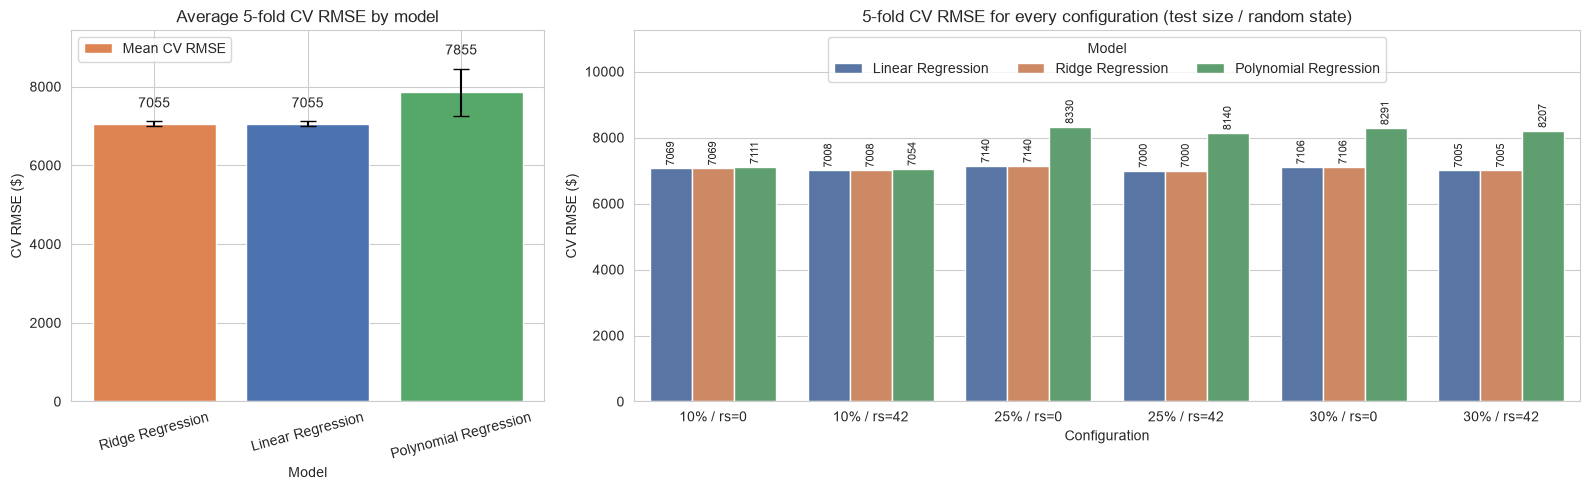

In [41]:
# Ei Htoo
# RMSE bar chart for the three models 
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})

# Same colour for each model in both panels
model_colors = {
    "Linear Regression": "#4C72B0",
    "Ridge Regression": "#DD8452",
    "Polynomial Regression": "#55A868"
}

# Left: average CV RMSE per model, error bars = spread across configurations
order = model_comparison.index.tolist()
bars = axes[0].bar(
    order,
    model_comparison["RMSE"],
    yerr=model_comparison["RMSE_Std_Across_Configs"].fillna(0),
    capsize=6,
    color=[model_colors[m] for m in order],
    label="Mean CV RMSE"
)
axes[0].bar_label(bars, fmt="%.0f", padding=8)
axes[0].set_title("Average 5-fold CV RMSE by model")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("CV RMSE ($)")
axes[0].set_ylim(0, model_comparison["RMSE"].max() * 1.2)
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend()

# Right: CV RMSE for every configuration
sns.barplot(data=all_cv, x="Config", y="CV RMSE Mean", hue="Model",
            palette=model_colors, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=2, fontsize=8, rotation=90)
axes[1].set_title("5-fold CV RMSE for every configuration (test size / random state)")
axes[1].set_xlabel("Configuration")
axes[1].set_ylabel("CV RMSE ($)")
axes[1].set_ylim(0, all_cv["CV RMSE Mean"].max() * 1.35)
axes[1].legend(title="Model", loc="upper center", ncol=3)

plt.tight_layout()
plt.show()

### The best model

1. Rank models by **mean cross-validated RMSE** across all configurations (lower is better).
2. If another model is within **0.5%** of the best RMSE, the difference is treated as noise and the **simpler** model wins (Linear, then Ridge, then Polynomial). MAE and R² are checked to make sure they agree.

In [33]:
# Ei Htoo
# The winning model
simplicity_rank = {"Linear Regression": 0, "Ridge Regression": 1, "Polynomial Regression": 2}
tolerance = 0.005

best_rmse = model_comparison["RMSE"].min()
close_enough = model_comparison[model_comparison["RMSE"] <= best_rmse * (1 + tolerance)]
winner = min(close_enough.index, key=lambda m: simplicity_rank[m])

print(f"Lowest mean CV RMSE: {model_comparison['RMSE'].idxmin()} ({best_rmse:,.2f})")
print(f"Models within {tolerance:.1%} of the best: {list(close_enough.index)}")
print(f"Selected model: {winner}")
print()
display(model_comparison.loc[[winner]].round(4))

# Use the winner's configuration with the lowest CV RMSE for the final test
winner_cfg = (
    all_cv[all_cv["Model"] == winner]
    .sort_values("CV RMSE Mean")
    .iloc[0]
)
final_test_size = float(winner_cfg["Test Size"])
final_rs = int(winner_cfg["Random State"])
print(f"Final evaluation split: test size {final_test_size:.0%}, random state {final_rs}")

Lowest mean CV RMSE: Ridge Regression (7,054.85)
Models within 0.5% of the best: ['Ridge Regression', 'Linear Regression']
Selected model: Linear Regression



,Configs,MAE,RMSE,RMSE_Std_Across_Configs,R2
Model,,,,,
Linear Regression,6,5288.4465,7054.8768,59.6581,0.0153


Final evaluation split: test size 25%, random state 42


### Final evaluation on the untouched test set
Only the selected model is fitted on the full training split and scored once on the held-out test set.

In [34]:
# Ei Htoo
# Fit the selected model and score it on the held-out test set
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X, y, test_size=final_test_size, random_state=final_rs
)

final_model = clone(models[winner])
final_model.fit(X_train_f, y_train_f)

# y is a one-column DataFrame, so flatten to 1-D arrays for metrics and plots
y_true = np.ravel(y_test_f)
y_hat = np.ravel(final_model.predict(X_test_f))
residuals = y_true - y_hat

final_mae = mean_absolute_error(y_true, y_hat)
final_rmse = np.sqrt(mean_squared_error(y_true, y_hat))
final_r2 = r2_score(y_true, y_hat)

final_results = pd.DataFrame([{
    "Model": winner,
    "Test Size": final_test_size,
    "Random State": final_rs,
    "Test MAE": final_mae,
    "Test RMSE": final_rmse,
    "Test R2": final_r2,
    "CV RMSE (same config)": winner_cfg["CV RMSE Mean"]
}])
display(final_results.round(4))

# Simple benchmark: always predict the training-set mean
baseline_pred = np.full_like(y_true, np.ravel(y_train_f).mean(), dtype=float)
print(f"Baseline (predict the mean) test RMSE: {np.sqrt(mean_squared_error(y_true, baseline_pred)):,.2f}")
print(f"Baseline (predict the mean) test MAE:  {mean_absolute_error(y_true, baseline_pred):,.2f}")

,Model,Test Size,Random State,Test MAE,Test RMSE,Test R2,CV RMSE (same config)
0,Linear Regression,0.25,42,5316.5932,7009.5947,0.0282,7000.2056


Baseline (predict the mean) test RMSE: 7,111.27
Baseline (predict the mean) test MAE:  5,390.19


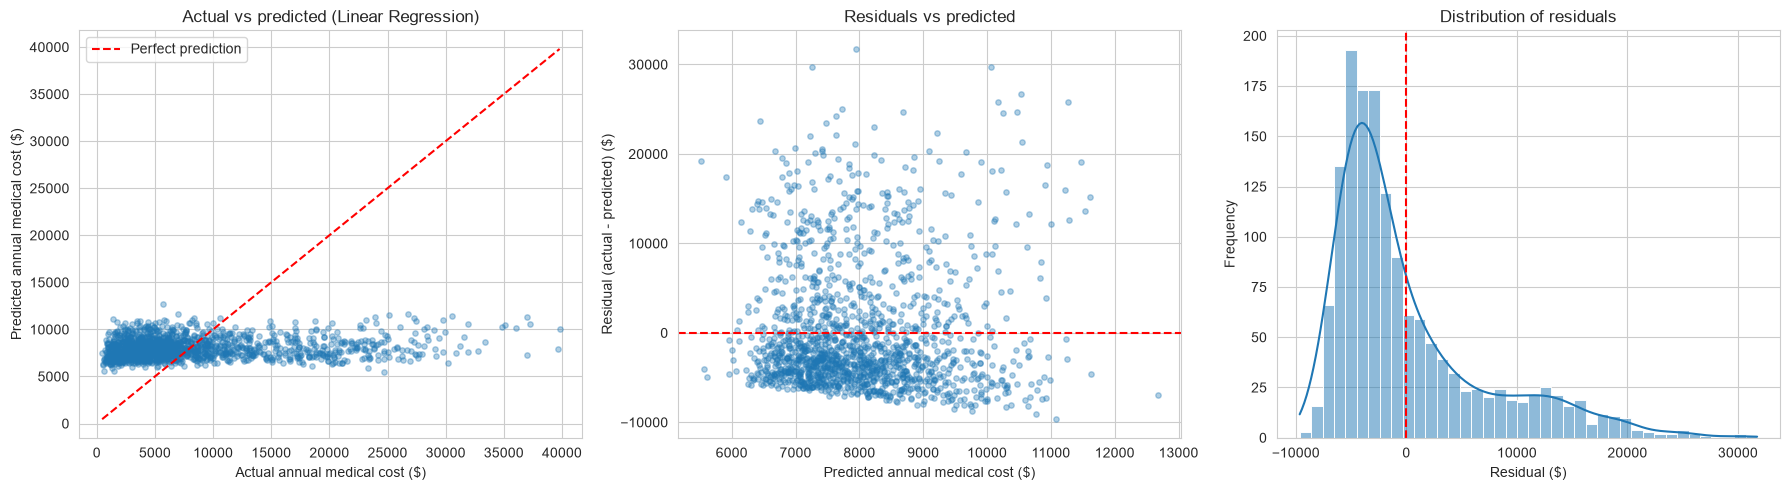

Mean residual: 115.13
Share of predictions within $2,000 of actual: 19.7%
Share of residuals that are positive (model underpredicts): 33.9%


In [ ]:
# Ei Htoo 
# Actual vs predicted, and residual plots 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs predicted
axes[0].scatter(y_true, y_hat, alpha=0.35, s=15)
lims = [min(y_true.min(), y_hat.min()), max(y_true.max(), y_hat.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_title(f"Actual vs predicted ({winner})")
axes[0].set_xlabel("Actual annual medical cost ($)")
axes[0].set_ylabel("Predicted annual medical cost ($)")
axes[0].legend()

# 2. Residuals vs predicted
axes[1].scatter(y_hat, residuals, alpha=0.35, s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs predicted")
axes[1].set_xlabel("Predicted annual medical cost ($)")
axes[1].set_ylabel("Residual (actual - predicted) ($)")

# 3. Residual distribution
sns.histplot(residuals, bins=40, kde=True, ax=axes[2])
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_title("Distribution of residuals")
axes[2].set_xlabel("Residual ($)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():,.2f}")
print(f"Share of predictions within $2,000 of actual: {(np.abs(residuals) <= 2000).mean():.1%}")
print(f"Share of residuals that are positive (model underpredicts): {(residuals > 0).mean():.1%}")

### Residual and error analysis
*Ei Htoo Khaing*

- **Actual vs predicted:** the points sit in a narrow horizontal band instead of following the red diagonal. The model predicts values close to the average for almost everyone, which matches the very low R² seen in cross-validation.
- **Residuals vs predicted:** residuals are not centred evenly around zero. Most of the large residuals are positive, meaning the model **underpredicts** the high-cost patients. The target is right-skewed, and a linear model fitted to squared error can't reach those tail values from these features.
- **Outliers:** the largest errors come from a small group of very expensive patients. Their cost is likely driven by hospital stays and treatment, which were removed from the features because they would leak the target.
- **Comparison to baseline:** the test RMSE is only slightly better than just predicting the average cost, so the features available before the year starts (demographics, lifestyle, chronic conditions) explain very little of the variation in cost.

In [ ]:
# Ei htoo
# Largest errors: which patients does the model miss most?
errors = X_test_f.copy()
errors["actual_cost"] = y_true
errors["predicted_cost"] = y_hat
errors["residual"] = residuals
errors["abs_error"] = np.abs(residuals)

# Outlier threshold: 1.5 x IQR above the third quartile of the absolute error
q1, q3 = np.percentile(errors["abs_error"], [25, 75])
outlier_cut = q3 + 1.5 * (q3 - q1)
outliers = errors[errors["abs_error"] > outlier_cut]

print(f"Large-error threshold: ${outlier_cut:,.0f}")
print(f"Test rows above the threshold: {len(outliers)} of {len(errors)} ({len(outliers)/len(errors):.1%})")
print(f"Of these, underpredicted (actual > predicted): {(outliers['residual'] > 0).mean():.1%}")

print("\nTop 10 largest errors")
display(
    errors.sort_values("abs_error", ascending=False)
    [["actual_cost", "predicted_cost", "residual", "diabetes", "hypertension",
      "heart_disease", "asthma"]]
    .head(10).round(2)
)

Large-error threshold: $11,977
Test rows above the threshold: 120 of 1250 (9.6%)
Of these, underpredicted (actual > predicted): 100.0%

Top 10 largest errors


,actual_cost,predicted_cost,residual,diabetes,hypertension,heart_disease,asthma
742,39680.9,7773.18,31907.72,0,1,0,1
3574,39795.2,10166.18,29629.02,0,0,1,0
2589,37285.8,10701.69,26584.11,0,1,1,0
4397,36012.7,10204.57,25808.13,0,0,1,0
4681,35143.0,10145.29,24997.71,1,1,0,0
3568,32795.7,7805.28,24990.42,0,1,0,0
1135,33354.4,8454.34,24900.06,1,0,0,0
2605,34857.5,10426.27,24431.23,0,1,1,0
2997,31235.5,8073.43,23162.07,1,1,0,0
1872,31610.2,9252.44,22357.76,0,0,1,0


### Export results to Excel

In [42]:
# Ei Htoo
# Export the comparison workbook
excel_name = "BDA500_Group14_Model_Comparison.xlsx"

feature_set = "Non-leakage features: 9 numeric + one-hot (gender, smoker, activity, city)"

reg_rows = []
for _, r in all_cv.iterrows():
    reg_rows.append({
        "Model": r["Model"],
        "Feature_Set": feature_set,
        "CV_or_Split": f"5-fold CV | test={r['Test Size']:.0%} | random_state={int(r['Random State'])}",
        "Best_Params": r["Params"],
        "MAE": round(r["CV MAE Mean"], 4),
        "RMSE": round(r["CV RMSE Mean"], 4),
        "R2": round(r["CV R2 Mean"], 4),
        "Notes": f"CV std: MAE {r['CV MAE Std']:.2f}, RMSE {r['CV RMSE Std']:.2f}, R2 {r['CV R2 Std']:.4f}"
    })

reg_rows.append({
    "Model": winner,
    "Feature_Set": feature_set,
    "CV_or_Split": f"Held-out test set | test={final_test_size:.0%} | random_state={final_rs}",
    "Best_Params": model_params[winner],
    "MAE": round(final_mae, 4),
    "RMSE": round(final_rmse, 4),
    "R2": round(final_r2, 4),
    "Notes": "Selected model, evaluated once on the untouched test set"
})

regression_results = pd.DataFrame(reg_rows)

with pd.ExcelWriter(excel_name, engine="openpyxl") as writer:
    regression_results.to_excel(writer, sheet_name="Regression_Results", index=False)
    model_comparison.round(4).reset_index().to_excel(writer, sheet_name="Model_Averages", index=False)

display(regression_results)

,Model,Feature_Set,CV_or_Split,Best_Params,MAE,RMSE,R2,Notes
0,Linear Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=10% | random_state=0,default,5311.1935,7069.4703,0.0123,"CV std: MAE 170.71, RMSE 271.81, R2 0.0213"
1,Linear Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=10% | random_state=42,default,5250.2874,7008.1660,0.0199,"CV std: MAE 178.90, RMSE 239.49, R2 0.0106"
2,Ridge Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=10% | random_state=0,alpha=1.0,5311.1398,7069.4223,0.0123,"CV std: MAE 170.79, RMSE 271.91, R2 0.0212"
3,Ridge Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=10% | random_state=42,alpha=1.0,5250.2420,7008.1358,0.0199,"CV std: MAE 178.83, RMSE 239.48, R2 0.0105"
4,Polynomial Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=10% | random_state=0,degree=3,5333.9217,7110.6850,0.0011,"CV std: MAE 189.89, RMSE 296.42, R2 0.0152"
5,Polynomial Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=10% | random_state=42,degree=3,5276.0023,7054.0009,0.0070,"CV std: MAE 162.77, RMSE 236.32, R2 0.0117"
6,Linear Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=25% | random_state=0,default,5391.1380,7140.4242,0.0148,"CV std: MAE 159.46, RMSE 352.66, R2 0.0173"
7,Linear Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=25% | random_state=42,default,5212.5112,7000.2056,0.0149,"CV std: MAE 124.51, RMSE 166.43, R2 0.0101"
8,Ridge Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=25% | random_state=0,alpha=1.0,5391.1163,7140.3996,0.0148,"CV std: MAE 159.47, RMSE 352.68, R2 0.0173"
9,Ridge Regression,Non-leakage features: 9 numeric + one-hot (gen...,5-fold CV | test=25% | random_state=42,alpha=1.0,5212.4820,7000.1873,0.0149,"CV std: MAE 124.50, RMSE 166.44, R2 0.0101"
